<a href="https://colab.research.google.com/github/AsfandyarFarooqi/learning-log/blob/main/week06_positioning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

## Monday: where am I, from distances?

In [ ]:
#saturday recap
A=np.array([[1,0],[-1,1],[0,1]])
lengths=np.array([3,1,2])
P=np.diag(1/lengths)
sigma=1
C_x=(sigma**2)*np.linalg.inv(A.T@P@A);
print("C_x->",C_x)
print("P->",np.sqrt(C_x[0,0]))
print("Q->",np.sqrt(C_x[1,1]))

C_x-> [[1.5        1.        ]
 [1.         1.33333333]]
P-> 1.224744871391589
Q-> 1.1547005383792515


In [ ]:
E_A, N_A = 0.0, 0.0
E0, N0 = 40.0, 30.0
d_before = np.sqrt((E0 - E_A)**2 + (N0 - N_A)**2)
d_after = np.sqrt((E0 + 0.001 - E_A)**2 + (N0 - N_A)**2)
print("distance before:", round(d_before, 6), "m")
print("distance after moving 1 mm east:", round(d_after, 6), "m")
print("change:", round((d_after - d_before) * 1000, 4), "mm")

distance before: 50.0 m
distance after moving 1 mm east: 50.0008 m
change: 0.8 mm


In [ ]:
ctrl = np.array([[0.0, 0.0],
                 [80.0, 0.0],
                 [40.0, 90.0]])
l = np.array([49.652, 48.007, 62.010])
x0 = np.array([40.0, 30.0])

diff = x0 - ctrl
d0 = np.sqrt(np.sum(diff**2, axis=1))
A = diff / d0.reshape(3, 1)
dl = l - d0
dx = np.linalg.solve(A.T @ A, A.T @ dl)
x1 = x0 + dx

print("diff =")
print(diff)
print("d0 =", d0)
print("A =")
print(A)
print("dl =", np.round(dl, 3))
print("A.T @ A =")
print(np.round(A.T @ A, 4))
print("A.T @ dl =", np.round(A.T @ dl, 4))
print("dx =", np.round(dx, 4))
print("x1 =", np.round(x1, 4))

diff =
[[ 40.  30.]
 [-40.  30.]
 [  0. -60.]]
d0 = [50. 50. 60.]
A =
[[ 0.8  0.6]
 [-0.8  0.6]
 [ 0.  -1. ]]
dl = [-0.348 -1.993  2.01 ]
A.T @ A =
[[ 1.28 -0.  ]
 [-0.    1.72]]
A.T @ dl = [ 1.316  -3.4146]
dx = [ 1.0281 -1.9852]
x1 = [41.0281 28.0148]


In [ ]:
x0 = x1
diff = x0 - ctrl
d0 = np.sqrt(np.sum(diff**2, axis=1))
A = diff / d0.reshape(3, 1)
dl = l - d0
dx = np.linalg.solve(A.T @ A, A.T @ dl)
x2 = x0 + dx
print("dx =", np.round(dx, 4))
print("x2 =", np.round(x2, 4))

dx = [-0.0241 -0.016 ]
x2 = [41.0041 27.9988]


In [ ]:
x0 = x2
diff = x0 - ctrl
d0 = np.sqrt(np.sum(diff**2, axis=1))
A = diff / d0.reshape(3, 1)
dl = l - d0
dx = np.linalg.solve(A.T @ A, A.T @ dl)
x3 = x0 + dx
print("dx =", np.round(dx, 4))
print("x3 =", np.round(x2, 4))

dx = [0. 0.]
x3 = [41.0041 27.9988]


In [ ]:
ctrl_pts=np.array([[0,0],[60,0],[30,100]])
measured=np.array([49.818,48.603,61.009])
x_o=np.array([30,40])
distances=np.sqrt(np.sum((x_o-ctrl_pts)**2,axis=1))
delta_l=measured-distances
A_= (x_o-ctrl_pts)/distances.reshape(3,1)
del_x=np.linalg.solve(A_.T@A_,A_.T@delta_l)
print(del_x)
new_x=x_o+del_x;
print('x_1',new_x)


[ 1.0125     -0.99657895]
x_1 [31.0125     39.00342105]


In [ ]:
ctrl = np.array([[0.0, 0.0],
                 [60.0, 0.0],
                 [30, 100]])
l = np.array([49.818, 48.603, 61.009])
x0 = np.array([40.0, 30.0])

In [ ]:
def free_station(ctrl, l, x0, stop=0.0001, max_rounds=10):
    x = np.array(x0, dtype=float)
    for round_no in range(1, max_rounds + 1):
        diff = x - ctrl
        d0 = np.sqrt(np.sum(diff**2, axis=1))
        A = diff / d0.reshape(len(l), 1)
        dl = l - d0
        dx = np.linalg.solve(A.T @ A, A.T @ dl)
        x = x + dx
        size = np.sqrt(dx[0]**2 + dx[1]**2)
        print("round", round_no, "| size of move:", round(size * 1000, 4), "mm | x:", np.round(x, 5))
        if size < stop:
            break
    return x

x_hat = free_station(ctrl, l, x0)

round 1 | size of move: 12044.4187 mm | x: [32.41425 39.35545]
round 2 | size of move: 1468.2928 mm | x: [30.98913 39.00202]
round 3 | size of move: 7.6865 mm | x: [30.99654 38.99997]
round 4 | size of move: 0.0001 mm | x: [30.99654 38.99997]


In [ ]:
diff = x_hat - ctrl
print("diff =")
print(diff)
d_hat = np.sqrt(np.sum(diff**2, axis=1))
r = l - d_hat
n = len(l)
u = 2
s0 = np.sqrt(np.sum(r**2) / (n - u))
print("distances computed from x_hat:", np.round(d_hat, 4))
print("residuals r (mm):", np.round(r * 1000, 2))
print("sum of squares (mm^2):", round(np.sum((r * 1000)**2), 4))
print("redundancy n - u =", n - u)
print("s0 =", round(s0 * 1000, 2), "mm")

diff =
[[ 30.99653824  38.99997085]
 [-29.00346176  38.99997085]
 [  0.99653824 -61.00002915]]
distances computed from x_hat: [49.8175 48.6025 61.0082]
residuals r (mm): [0.5  0.55 0.83]
sum of squares (mm^2): 1.2414
redundancy n - u = 1
s0 = 1.11 mm


## Thursday: how sure are we of S?

In [ ]:
import matplotlib.pyplot as plt

ctrl = np.array([[0.0, 0.0],
                 [80.0, 0.0],
                 [40.0, 90.0]])
l = np.array([49.652, 48.007, 62.010])
x0 = np.array([40.0, 30.0])

def free_station(ctrl, l, x0, stop=0.0001, max_rounds=10, show=True):
    x = np.array(x0, dtype=float)
    for round_no in range(1, max_rounds + 1):
        diff = x - ctrl
        d0 = np.sqrt(np.sum(diff**2, axis=1))
        A = diff / d0.reshape(len(l), 1)
        dl = l - d0
        dx = np.linalg.solve(A.T @ A, A.T @ dl)
        x = x + dx
        size = np.sqrt(dx[0]**2 + dx[1]**2)
        if show:
            print("round", round_no, "| size of move:", round(size * 1000, 4), "mm | x:", np.round(x, 5))
        if size < stop:
            break
    return x

x_hat = free_station(ctrl, l, x0)
print(x_hat)

round 1 | size of move: 2235.6631 mm | x: [41.02813 28.01477]
round 2 | size of move: 28.8908 mm | x: [41.00405 27.99879]
round 3 | size of move: 0.0042 mm | x: [41.00406 27.99879]
[41.00405853 27.99879006]


In [ ]:
diff = x_hat - ctrl
d_hat = np.sqrt(np.sum(diff**2, axis=1))
A = diff / d_hat.reshape(3, 1)
r = l - d_hat
s0_hat = np.sqrt(np.sum(r**2) / (3 - 2))

AtA = A.T @ A
C_x = s0_hat**2 * np.linalg.inv(AtA)
sig_E = np.sqrt(C_x[0, 0])
sig_N = np.sqrt(C_x[1, 1])

print("A at x_hat:\n", np.round(A, 4))
print("AtA:\n", np.round(AtA, 4))
print("s0_hat:", round(s0_hat * 1000, 4), "mm")
print("C_x in mm^2:\n", np.round(C_x * 1e6, 4))
print("sigma E:", round(sig_E * 1000, 3), "mm | sigma N:", round(sig_N * 1000, 3), "mm")

A at x_hat:
 [[ 0.8258  0.5639]
 [-0.8123  0.5832]
 [ 0.0162 -0.9999]]
AtA:
 [[ 1.3421 -0.0243]
 [-0.0243  1.6579]]
s0_hat: 1.0485 mm
C_x in mm^2:
 [[0.8194 0.012 ]
 [0.012  0.6633]]
sigma E: 0.905 mm | sigma N: 0.814 mm


In [ ]:
S_true = np.array([41.0, 28.0])
d_true = np.sqrt(np.sum((S_true - ctrl)**2, axis=1))

rng = np.random.default_rng(1)
answers = []
for k in range(500):
    noise = rng.normal(0, 0.001, size=3)
    l_sim = d_true + noise
    x_sim = free_station(ctrl, l_sim, x0, show=False)
    answers.append(x_sim)

answers = np.array(answers)
off_mm = (answers - S_true) * 1000

print("true distances:", np.round(d_true, 5))
print("shape of answers:", answers.shape)
print("first 3 answers:\n", np.round(answers[:3], 5))
print("spread of E:", round(np.std(off_mm[:, 0]), 3), "mm")
print("spread of N:", round(np.std(off_mm[:, 1]), 3), "mm")

true distances: [49.64877 48.01042 62.00806]
shape of answers: (500, 2)
first 3 answers:
 [[40.99972 28.0002 ]
 [40.99865 27.99959]
 [40.99932 27.99979]]
spread of E: 0.851 mm
spread of N: 0.808 mm


In [ ]:
A_t = (S_true - ctrl) / d_true.reshape(3, 1)
C_t = 0.001**2 * np.linalg.inv(A_t.T @ A_t)
sig_E_t = np.sqrt(C_t[0, 0])
sig_N_t = np.sqrt(C_t[1, 1])
print("formula sigma E:", round(sig_E_t * 1000, 3), "mm | formula sigma N:", round(sig_N_t * 1000, 3), "mm")

inside = np.abs(off_mm[:, 0]) < sig_E_t * 1000
print("share of surveys with E error inside +-1 sigma:", np.mean(inside))

formula sigma E: 0.863 mm | formula sigma N: 0.777 mm
share of surveys with E error inside +-1 sigma: 0.68


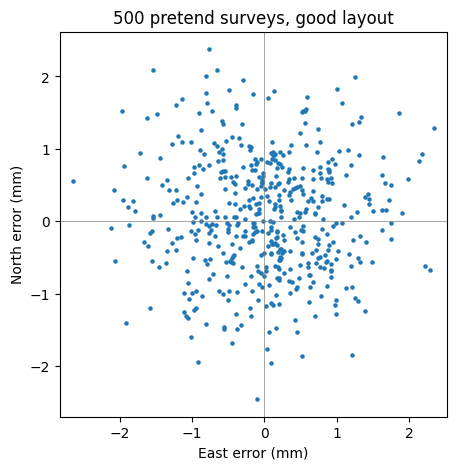

In [ ]:
plt.figure(figsize=(5, 5))
plt.scatter(off_mm[:, 0], off_mm[:, 1], s=5)
plt.axhline(0, color="grey", linewidth=0.5)
plt.axvline(0, color="grey", linewidth=0.5)
plt.xlabel("East error (mm)")
plt.ylabel("North error (mm)")
plt.title("500 pretend surveys, good layout")
plt.axis("equal")
plt.show()

In [ ]:
ctrl_bad = np.array([[0.0, 0.0],
                     [10.0, 0.0],
                     [20.0, 0.0]])
d_true_b = np.sqrt(np.sum((S_true - ctrl_bad)**2, axis=1))
A_b = (S_true - ctrl_bad) / d_true_b.reshape(3, 1)
C_b = 0.001**2 * np.linalg.inv(A_b.T @ A_b)

print("A_b:\n", np.round(A_b, 4))
print("C_b in mm^2:\n", np.round(C_b * 1e6, 3))
print("formula sigma E:", round(np.sqrt(C_b[0, 0]) * 1000, 3), "mm | formula sigma N:", round(np.sqrt(C_b[1, 1]) * 1000, 3), "mm")

A_b:
 [[0.8258 0.564 ]
 [0.7421 0.6703]
 [0.6    0.8   ]]
C_b in mm^2:
 [[ 8.865 -9.09 ]
 [-9.09  10.032]]
formula sigma E: 2.977 mm | formula sigma N: 3.167 mm


spread of E: 3.035 mm | spread of N: 3.217 mm


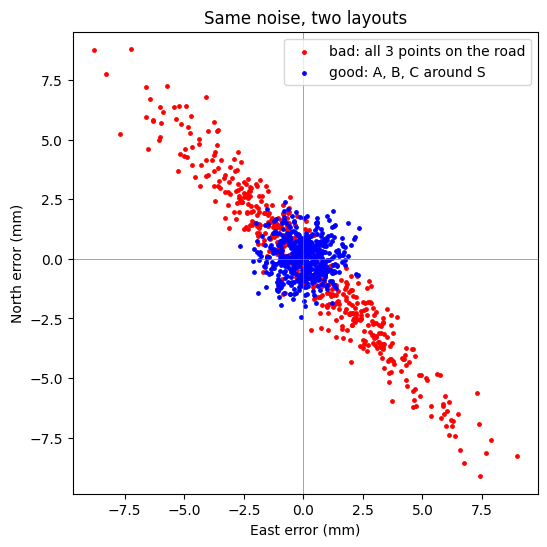

In [ ]:
rng = np.random.default_rng(1)
answers_b = []
for k in range(500):
    noise = rng.normal(0, 0.001, size=3)
    l_sim = d_true_b + noise
    x_sim = free_station(ctrl_bad, l_sim, x0, show=False)
    answers_b.append(x_sim)

answers_b = np.array(answers_b)
off_b_mm = (answers_b - S_true) * 1000
print("spread of E:", round(np.std(off_b_mm[:, 0]), 3), "mm | spread of N:", round(np.std(off_b_mm[:, 1]), 3), "mm")

plt.figure(figsize=(6, 6))
plt.scatter(off_b_mm[:, 0], off_b_mm[:, 1], s=6, color="red", label="bad: all 3 points on the road")
plt.scatter(off_mm[:, 0], off_mm[:, 1], s=6, color="blue", label="good: A, B, C around S")
plt.axhline(0, color="grey", linewidth=0.5)
plt.axvline(0, color="grey", linewidth=0.5)
plt.xlabel("East error (mm)")
plt.ylabel("North error (mm)")
plt.title("Same noise, two layouts")
plt.legend()
plt.axis("equal")
plt.show()

## Friday: GNSS on a flat map

In [ ]:
ctrl = np.array([[0.0, 0.0],
                 [60.0, 100.0],
                 [30, 100.0]])
x0 = np.array([40.0, 30.0])
rho = np.array([37.818,36.603,49.009])

x_old = free_station(ctrl, rho, x0)
d_old = np.sqrt(np.sum((x_old - ctrl)**2, axis=1))
print("residuals (m):", np.round(rho - d_old, 3))

round 1 | size of move: 40163.0066 mm | x: [12.24832 59.03294]
round 2 | size of move: 74557.2552 mm | x: [77.95452 23.7983 ]
round 3 | size of move: 56347.1303 mm | x: [27.10798 48.08056]
round 4 | size of move: 8980.7665 mm | x: [36.08691 48.26226]
round 5 | size of move: 21027.3289 mm | x: [16.41991 55.70255]
round 6 | size of move: 77947.8771 mm | x: [86.91655 22.44454]
round 7 | size of move: 62190.2364 mm | x: [29.03529 45.19064]
round 8 | size of move: 9979.3498 mm | x: [23.45582 53.46452]
round 9 | size of move: 45642.868 mm | x: [65.2801  35.18881]
round 10 | size of move: 46832.5517 mm | x: [20.79765 49.83802]
residuals (m): [-16.185 -27.061  -1.99 ]


In [ ]:
def gnss_2d(ctrl, rho, x0, stop=0.0001, max_rounds=10, show=True):
    x = np.array(x0, dtype=float)
    n = len(rho)
    for round_no in range(1, max_rounds + 1):
        diff = x[:2] - ctrl
        d0 = np.sqrt(np.sum(diff**2, axis=1))
        A = np.ones((n, 3))
        A[:, :2] = diff / d0.reshape(n, 1)
        drho = rho - (d0 + x[2])
        dx = np.linalg.solve(A.T @ A, A.T @ drho)
        x = x + dx
        size = np.sqrt(np.sum(dx**2))
        if show:
            print("round", round_no, "| size of move:", round(size * 1000, 4), "mm | E, N, b:", np.round(x, 5))
        if size < stop:
            break
    return x

x_g = gnss_2d(ctrl, rho, np.array([40.0, 30.0, 0]))

round 1 | size of move: 49442.3879 mm | E, N, b: [ 74.27446  21.79046 -34.67585]
round 2 | size of move: 13465.9118 mm | E, N, b: [ 81.42557  19.99928 -45.94457]
round 3 | size of move: 737.2128 mm | E, N, b: [ 81.9194   19.86447 -46.47508]
round 4 | size of move: 3.4492 mm | E, N, b: [ 81.92172  19.86378 -46.47754]
round 5 | size of move: 0.0001 mm | E, N, b: [ 81.92172  19.86378 -46.47754]


In [ ]:
d_g = np.sqrt(np.sum((x_g[:2] - ctrl)**2, axis=1))
r_g = rho - (d_g + x_g[2])
print("residuals (mm):", r_g * 1000)
print("error vs truth (mm): E", round((x_g[0] - 41) * 1000, 2), "| N", round((x_g[1] - 28) * 1000, 2), "| b", round((x_g[2] - 25) * 1000, 2))

residuals (mm): [ 1.42108547e-11 -7.10542736e-12  0.00000000e+00]
error vs truth (mm): E 40921.72 | N -8136.22 | b -71477.54


##Saturday: GNSS in 3D

In [2]:
np.set_printoptions(suppress=True)

sats = np.array([[0.000, 0.000, 20200000.000],
                 [19750575.359, 0.000, 11403000.000],
                 [-5243436.299, -14406222.832, 15330782.123],
                 [-19294329.227, 11139586.173, 8108955.578],
                 [11687702.498, -20243694.550, 6263420.891],
                 [6051231.404, 10481040.239, 17284108.134],
                 [9033510.987, -5215500.000, 18067021.974]])
rho = np.array([20202999.025, 22808987.033, 21683990.555, 23712009.353,
                24202984.497, 21102994.803, 20864990.181])
x0 = np.array([0.0, 0.0, 0.0, 0.0])

d0 = np.sqrt(np.sum((x0[:3] - sats)**2, axis=1))
print("distances from the guess (km):", np.round(d0 / 1000, 3))
print("first gaps rho - (d0 + 0) (m):", np.round(rho - d0, 3))

distances from the guess (km): [20200. 22806. 21681. 23709. 24200. 21100. 20862.]
first gaps rho - (d0 + 0) (m): [2999.025 2987.033 2990.555 3009.353 2984.498 2994.803 2990.181]


In [3]:
def gnss_3d(sats, rho, x0, stop=0.0001, max_rounds=10, show=True):
    x = np.array(x0, dtype=float)
    n = len(rho)
    for round_no in range(1, max_rounds + 1):
        diff = x[:3] - sats
        d0 = np.sqrt(np.sum(diff**2, axis=1))
        A = np.ones((n, 4))

        A[:, :3] = diff / d0.reshape(n, 1)

        drho = rho - (d0 + x[3])

        dx = np.linalg.solve(A.T @ A, A.T @ drho)
        x = x + dx
        size = np.sqrt(np.sum(dx**2))
        if show:
            print("round", round_no, "| size of move:", round(size * 1000, 4), "mm | E, N, U, b:", np.round(x, 3))
        if size < stop:
            break
    return x

x_hat = gnss_3d(sats, rho, x0)

round 1 | size of move: 2995893.7492 mm | E, N, U, b: [  10.574   -8.463   -0.391 2995.863]
round 2 | size of move: 0.0058 mm | E, N, U, b: [  10.574   -8.463   -0.391 2995.863]


In [ ]:
diff = x_hat[:3] - sats
d_hat = np.sqrt(np.sum(diff**2, axis=1))
r = rho - (d_hat + x_hat[3])
s0_hat = np.sqrt(np.sum(r**2) / (7 - 4))

print("residuals (m):", np.round(r, 2))
print("s0_hat (m):", round(s0_hat, 2))
print("error vs truth (m): E", round(x_hat[0] - 12, 2), "| N", round(x_hat[1] + 7, 2), "| U", round(x_hat[2] - 3, 2), "| b", round(x_hat[3] - 2997.925, 2))

residuals (m): [ 2.77  0.13 -2.52  0.77  0.72 -2.55  0.67]
s0_hat (m): 2.72
error vs truth (m): E -1.43 | N -1.46 | U -3.39 | b -2.06


In [ ]:
A = np.ones((7, 4))
A[:, :3] = diff / d_hat.reshape(7, 1)
Q = np.linalg.inv(A.T @ A)
s0 = 3.0
sig = s0 * np.sqrt(np.diag(Q))

print("A (rates):\n", np.round(A, 4))
print("A.T @ A:\n", np.round(A.T @ A, 4))
print("sigma E, N, U, b (m):", np.round(sig, 2))
print("HDOP:", round(np.sqrt(Q[0, 0] + Q[1, 1]), 2), "| VDOP:", round(np.sqrt(Q[2, 2]), 2))
print("correlation U-b:", round(Q[2, 3] / np.sqrt(Q[2, 2] * Q[3, 3]), 2), "| correlation E-b:", round(Q[0, 3] / np.sqrt(Q[0, 0] * Q[3, 3]), 2))

A (rates):
 [[ 0.     -0.     -1.      1.    ]
 [-0.866  -0.     -0.5     1.    ]
 [ 0.2418  0.6645 -0.7071  1.    ]
 [ 0.8138 -0.4698 -0.342   1.    ]
 [-0.483   0.8365 -0.2588  1.    ]
 [-0.2868 -0.4967 -0.8192  1.    ]
 [-0.433   0.25   -0.866   1.    ]]
A.T @ A:
 [[ 1.9738 -0.5915  0.7186 -1.0131]
 [-0.5915  1.6713 -0.3353  0.7844]
 [ 0.7186 -0.3353  3.355  -4.4931]
 [-1.0131  0.7844 -4.4931  7.    ]]
sigma E, N, U, b (m): [2.33 2.55 4.5  3.14]
HDOP: 1.15 | VDOP: 1.5
correlation U-b: 0.93 | correlation E-b: -0.05


In [25]:
visible_sats=sats[[0,2,5,6]]
rho_visible=rho[[0,2,5,6]]

x_hat_visible=gnss_3d(visible_sats,rho_visible,np.array([0,0,0,0]))

diff_visible = x_hat_visible[:3] - visible_sats
d_hat_visible = np.sqrt(np.sum(diff_visible**2, axis=1))
r_visible = rho_visible - (d_hat_visible + x_hat_visible[3])
s0_hat_visible = np.sqrt(np.sum(r_visible**2) / (7 - 4))

print("residuals (m):", np.round(r_visible, 2))
print("s0_hat_visible (m):", round(s0_hat_visible, 2))

A = np.ones((4, 4))
A[:, :3] = diff_visible / d_hat_visible.reshape(4, 1)
Q = np.linalg.inv(A.T @ A)
s0 = 3.0
sig = s0_hat_visible * np.sqrt(np.diag(Q))

print("A (rates):\n", np.round(A, 4))
print("A.T @ A:\n", np.round(A.T @ A, 4))
print("sigma E, N, U, b (m):", np.round(sig, 2))
print("HDOP:", round(np.sqrt(Q[0, 0] + Q[1, 1]), 2), "| VDOP:", round(np.sqrt(Q[2, 2]), 2))
print("correlation U-b:", round(Q[2, 3] / np.sqrt(Q[2, 2] * Q[3, 3]), 2), "| correlation E-b:", round(Q[0, 3] / np.sqrt(Q[0, 0] * Q[3, 3]), 2))


round 1 | size of move: 2975320.4929 mm | E, N, U, b: [   9.716   -5.783  -23.821 2975.204]
round 2 | size of move: 0.035 mm | E, N, U, b: [   9.716   -5.783  -23.821 2975.204]
residuals (m): [0. 0. 0. 0.]
s0_hat_visible (m): 0.0
A (rates):
 [[ 0.     -0.     -1.      1.    ]
 [ 0.2418  0.6645 -0.7071  1.    ]
 [-0.2868 -0.4967 -0.8192  1.    ]
 [-0.433   0.25   -0.866   1.    ]]
A.T @ A:
 [[ 0.3282  0.1949  0.4389 -0.478 ]
 [ 0.1949  0.7508 -0.2795  0.4177]
 [ 0.4389 -0.2795  2.921  -3.3923]
 [-0.478   0.4177 -3.3923  4.    ]]
sigma E, N, U, b (m): [0. 0. 0. 0.]
HDOP: 2.78 | VDOP: 5.28
correlation U-b: 0.99 | correlation E-b: -0.01
